In [2]:
import os, glob, numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

BASE     = '/content/drive/MyDrive/Glaucoma_new'
MASK_DIR = f'{BASE}/G1020_masks'      # masks
IMG_DIR  = f'{BASE}/G1020_cropped'    # cropped images (for overlay check only)
OUT      = f'{BASE}/results'
os.makedirs(OUT, exist_ok=True)

# optional: label file, used in Cell 3 (set to None if you do not have it)
LABEL_CSV = '/content/drive/MyDrive/glaucoma/raw/G1020/G1020.csv'

EXT = ('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp')
mask_files = sorted(f for f in glob.glob(f'{MASK_DIR}/**/*', recursive=True)
                    if f.lower().endswith(EXT))
print('masks found:', len(mask_files))
print('example files:', [os.path.basename(f) for f in mask_files[:3]])

# look at the first 5 masks: shape and pixel values
for f in mask_files[:5]:
    m = cv2.imread(f, cv2.IMREAD_UNCHANGED)
    vals, cnt = np.unique(m.reshape(-1, m.shape[-1]) if m.ndim == 3 else m, axis=0 if m.ndim == 3 else None,
                          return_counts=True)
    print(os.path.basename(f), '| shape', m.shape, '| dtype', m.dtype, '| values:', dict(zip(map(str, vals.tolist()), cnt.tolist())))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
masks found: 1020
example files: ['image_0.png', 'image_1.png', 'image_10.png']
image_0.png | shape (2423, 3004) | dtype uint8 | values: {'0': 7116252, '1': 142174, '2': 20266}
image_1.png | shape (2424, 3005) | dtype uint8 | values: {'0': 7116045, '1': 120218, '2': 47857}
image_10.png | shape (2425, 3006) | dtype uint8 | values: {'0': 7101285, '1': 188265}
image_1000.png | shape (2424, 3004) | dtype uint8 | values: {'0': 7141494, '1': 104987, '2': 35215}
image_1001.png | shape (1944, 2108) | dtype uint8 | values: {'0': 4013938, '1': 52923, '2': 31091}


In [4]:
def read_labels(path):
    """Read a mask and return an integer label image (0..k-1), ordered by brightness."""
    m = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if m is None:
        return None
    if m.ndim == 3:
        if m.shape[2] == 4: m = m[:, :, :3]
        if (m[:, :, 0] == m[:, :, 1]).all() and (m[:, :, 1] == m[:, :, 2]).all():
            m = m[:, :, 0]                              # grey stored as 3 channels
        else:                                           # colour mask -> rank colours by brightness
            flat = m.reshape(-1, 3)
            cols, inv = np.unique(flat, axis=0, return_inverse=True)
            order = np.argsort(cols.sum(1))
            rank = np.empty_like(order); rank[order] = np.arange(len(order))
            return rank[inv.reshape(-1)].reshape(m.shape[:2]).astype(np.int32)
    vals = np.unique(m)
    return np.searchsorted(vals, m).astype(np.int32)

def v_extent(binary):
    rows = np.where(binary.any(axis=1))[0]
    return 0 if len(rows) == 0 else rows.max() - rows.min() + 1

def h_extent(binary):
    cols = np.where(binary.any(axis=0))[0]
    return 0 if len(cols) == 0 else cols.max() - cols.min() + 1

def largest_component(binary):
    """Remove small noise blobs: keep only the biggest connected region."""
    b = binary.astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(b, connectivity=8)
    if n <= 1: return binary
    k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return lab == k

# ---- 1) Decide which label is background / cup, using a sample of masks ----
SAMPLE = mask_files[:60]
tot = {}
ext = {}
for f in SAMPLE:
    L = read_labels(f)
    for v in np.unique(L):
        tot[v] = tot.get(v, 0) + int((L == v).sum())
        ext.setdefault(v, []).append(v_extent(L == v))
BG_LABEL = max(tot, key=tot.get)                                  # most frequent = background
fg = [v for v in tot if v != BG_LABEL]
assert len(fg) >= 2, f'Only {len(fg)} foreground label(s) found: disc and cup are not in one mask.'
# cup = foreground label with the smaller vertical extent (cup is inside the disc)
CUP_LABEL = min(fg, key=lambda v: np.median(ext[v]))
print('background label:', BG_LABEL, '| foreground labels:', fg, '| cup label:', CUP_LABEL)
print('median vertical extents:', {int(v): float(np.median(ext[v])) for v in fg})

# Manual override if the overlay in Cell 3 shows this guess is wrong:
# CUP_LABEL = 2

# ---- 2) Compute CDRs ----
rows = []
for f in mask_files:
    L = read_labels(f)
    stem = os.path.splitext(os.path.basename(f))[0]
    if L is None:
        rows.append(dict(stem=stem, status='unreadable')); continue
    disc = largest_component(L != BG_LABEL)          # disc = everything that is not background
    cup  = largest_component(L == CUP_LABEL)
    cup  = cup & disc                                 # cup must lie inside the disc
    dv, cv_ = v_extent(disc), v_extent(cup)
    dh, ch  = h_extent(disc), h_extent(cup)
    if dv == 0 or cv_ == 0:
        rows.append(dict(stem=stem, status='empty disc or cup')); continue
    rows.append(dict(stem=stem, status='ok',
                     disc_v=dv, cup_v=cv_, disc_h=dh, cup_h=ch,
                     disc_area=int(disc.sum()), cup_area=int(cup.sum()),
                     vCDR=cv_ / dv, hCDR=ch / dh,
                     area_CDR=cup.sum() / disc.sum()))

res = pd.DataFrame(rows)
print(res.status.value_counts())
print(res[res.status == 'ok'][['vCDR', 'hCDR', 'area_CDR']].describe().round(3))

bad = res[(res.status == 'ok') & ((res.vCDR > 1) | (res.vCDR < 0.05))]
print('suspicious vCDR (>1 or <0.05):', len(bad))

res.to_csv(f'{OUT}/G1020_vCDR.csv', index=False)
print('saved', f'{OUT}/G1020_vCDR.csv')


background label: 0 | foreground labels: [np.int32(1), np.int32(2)] | cup label: 2
median vertical extents: {1: 453.0, 2: 179.5}
status
ok                   790
empty disc or cup    230
Name: count, dtype: int64
          vCDR     hCDR  area_CDR
count  790.000  790.000   790.000
mean     0.463    0.466     0.221
std      0.098    0.097     0.092
min      0.212    0.224     0.049
25%      0.394    0.405     0.159
50%      0.455    0.454     0.203
75%      0.520    0.520     0.265
max      0.789    0.800     0.618
suspicious vCDR (>1 or <0.05): 0
saved /content/drive/MyDrive/Glaucoma_new/results/G1020_vCDR.csv


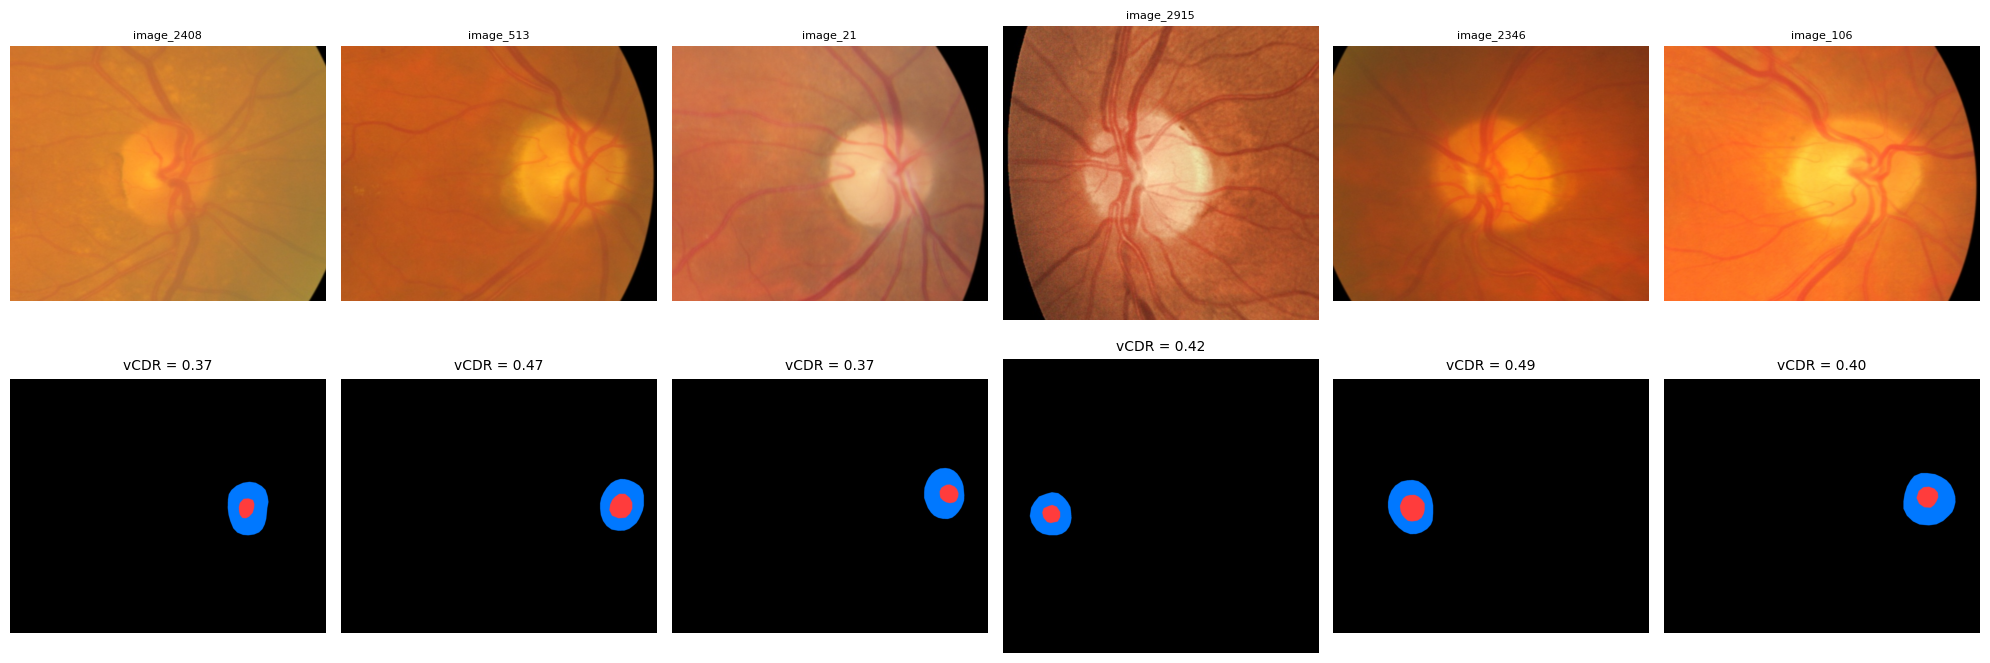

rows without label: 0
        vCDR                 hCDR               area_CDR              
        mean    std median   mean    std median     mean    std median
label                                                                 
0      0.461  0.098  0.453  0.462  0.095  0.451    0.218  0.091  0.200
1      0.469  0.097  0.465  0.474  0.100  0.465    0.228  0.093  0.212
AUC using vCDR alone: 0.526
AUC using hCDR alone: 0.536
AUC using area_CDR alone: 0.533
Best vCDR threshold (Youden): 0.425 | sens 0.67 | spec 0.40


/tmp/ipykernel_1418/4240315633.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([d[d.label == 0].vCDR, d[d.label == 1].vCDR], labels=['Normal', 'Glaucoma'])


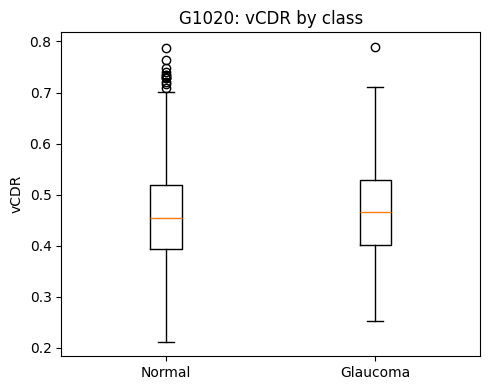

In [5]:
# ---- A) Overlay check: always look at these before trusting the numbers ----
img_files = {os.path.splitext(os.path.basename(f))[0]: f for f in
             glob.glob(f'{IMG_DIR}/**/*', recursive=True) if f.lower().endswith(EXT)}
mask_by_stem = {os.path.splitext(os.path.basename(f))[0]: f for f in mask_files}
ok = res[res.status == 'ok'].sample(6, random_state=0)

fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for j, (_, r) in enumerate(ok.iterrows()):
    L = read_labels(mask_by_stem[r.stem])
    show = np.zeros((*L.shape, 3), np.uint8)
    show[L != BG_LABEL] = (0, 120, 255)       # disc = blue
    show[L == CUP_LABEL] = (255, 60, 60)      # cup = red
    if r.stem in img_files:
        im = cv2.cvtColor(cv2.imread(img_files[r.stem]), cv2.COLOR_BGR2RGB)
        im = cv2.resize(im, (L.shape[1], L.shape[0]))
        axes[0, j].imshow(im)
    axes[0, j].set_title(r.stem, fontsize=8); axes[0, j].axis('off')
    axes[1, j].imshow(show); axes[1, j].set_title(f'vCDR = {r.vCDR:.2f}', fontsize=10); axes[1, j].axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/G1020_vCDR_overlay_check.png', dpi=120); plt.show()

# ---- B) Merge with glaucoma labels (if available) ----
if LABEL_CSV and os.path.exists(LABEL_CSV):
    lab = pd.read_csv(LABEL_CSV)
    lab['stem'] = lab['imageID'].astype(str).apply(lambda s: os.path.splitext(s)[0])
    lab = lab.rename(columns={'binaryLabels': 'label'})[['stem', 'label']]
    full = res.merge(lab, on='stem', how='left')
    print('rows without label:', int(full.label.isna().sum()))
    full.to_csv(f'{OUT}/G1020_vCDR_with_labels.csv', index=False)

    d = full[(full.status == 'ok') & full.label.notna()].copy()
    print(d.groupby('label')[['vCDR', 'hCDR', 'area_CDR']].agg(['mean', 'std', 'median']).round(3))

    # ---- C) How well does vCDR alone separate glaucoma from normal? ----
    from sklearn.metrics import roc_auc_score, roc_curve
    y = d.label.astype(int).values
    for col in ['vCDR', 'hCDR', 'area_CDR']:
        print(f'AUC using {col} alone: {roc_auc_score(y, d[col]):.3f}')
    fpr, tpr, th = roc_curve(y, d.vCDR)
    best = np.argmax(tpr - fpr)
    print(f'Best vCDR threshold (Youden): {th[best]:.3f} | sens {tpr[best]:.2f} | spec {1 - fpr[best]:.2f}')

    plt.figure(figsize=(5, 4))
    plt.boxplot([d[d.label == 0].vCDR, d[d.label == 1].vCDR], labels=['Normal', 'Glaucoma'])
    plt.ylabel('vCDR'); plt.title('G1020: vCDR by class')
    plt.tight_layout(); plt.savefig(f'{OUT}/G1020_vCDR_boxplot.png', dpi=150); plt.show()
else:
    print('Label CSV not found: only the vCDR values were saved.')
